# Часть C. KNN Regression

датасет - Seoul Bike Sharing Demand, целевая переменная - `Rented Bike Count`.

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from knn import KNN

SEED = 67

## Загрузка и исследование

In [12]:
df = pd.read_csv("data/SeoulBikeData.csv", encoding="latin1")
print("Размер:", df.shape)
df.head()

Размер: (8760, 14)


,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


In [13]:
print("Столбцы:", df.columns.tolist())
print("Пропусков:", df.isna().sum().sum())
df.dtypes

Столбцы: ['Date', 'Rented Bike Count', 'Hour', 'Temperature(°C)', 'Humidity(%)', 'Wind speed (m/s)', 'Visibility (10m)', 'Dew point temperature(°C)', 'Solar Radiation (MJ/m2)', 'Rainfall(mm)', 'Snowfall (cm)', 'Seasons', 'Holiday', 'Functioning Day']
Пропусков: 0


Date                             str
Rented Bike Count              int64
Hour                           int64
Temperature(°C)              float64
Humidity(%)                    int64
Wind speed (m/s)             float64
Visibility (10m)               int64
Dew point temperature(°C)    float64
Solar Radiation (MJ/m2)      float64
Rainfall(mm)                 float64
Snowfall (cm)                float64
Seasons                          str
Holiday                          str
Functioning Day                  str
dtype: object

count    8760.000000
mean      704.602055
std       644.997468
min         0.000000
25%       191.000000
50%       504.500000
75%      1065.250000
max      3556.000000
Name: Rented Bike Count, dtype: float64


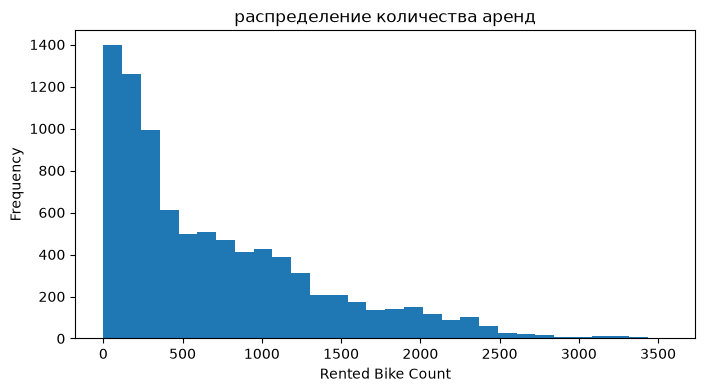

In [14]:
print(df["Rented Bike Count"].describe())

df["Rented Bike Count"].plot(kind="hist", bins=30, figsize=(8, 4))
plt.title("распределение количества аренд")
plt.xlabel("Rented Bike Count")
plt.show()

в датасете 8760 строк и 14 столбцов, пропусков нет. 

Целевая переменная имеет правостороннее распределение: небольших значений много, а очень больших - заметно меньше.

## X и y

In [15]:
X = df.drop(columns="Rented Bike Count")
y = df["Rented Bike Count"]

print("X:", X.shape)
print("y:", y.shape)

X: (8760, 13)
y: (8760,)


## Train/validation/test split

перемешиваем индексы с фиксированным seed и делим данные в отношении 60 / 20 / 20.

In [16]:
indices = np.random.default_rng(SEED).permutation(len(X))
train_end = int(0.6 * len(X))
val_end = int(0.8 * len(X))

train_idx = indices[:train_end]
val_idx = indices[train_end:val_end]
test_idx = indices[val_end:]

X_train = X.iloc[train_idx].reset_index(drop=True)
X_val = X.iloc[val_idx].reset_index(drop=True)
X_test = X.iloc[test_idx].reset_index(drop=True)

y_train = y.iloc[train_idx].reset_index(drop=True)
y_val = y.iloc[val_idx].reset_index(drop=True)
y_test = y.iloc[test_idx].reset_index(drop=True)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (5256, 13)
Validation: (1752, 13)
Test: (1752, 13)


## Preprocessing

из даты получаем месяц, день месяца и день недели. 

Категориальные признаки преобразуем через `get_dummies`.

In [17]:
numeric_cols = X_train.select_dtypes(include="number").columns.tolist() + ["Day"]
cat_cols = ["Seasons", "Holiday", "Functioning Day", "Month", "Weekday"]


def prepare_features(data):
    data = data.copy()
    dates = pd.to_datetime(data["Date"], format="%d/%m/%Y")
    data["Month"] = dates.dt.month
    data["Day"] = dates.dt.day
    data["Weekday"] = dates.dt.dayofweek
    data = data.drop(columns="Date")
    return pd.get_dummies(data, columns=cat_cols, dtype=int)


X_train = prepare_features(X_train)
X_val = prepare_features(X_val)
X_test = prepare_features(X_test)

X_val = X_val.reindex(columns=X_train.columns, fill_value=0)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("Признаков после preprocessing:", X_train.shape[1])

Признаков после preprocessing: 37


## Scaling

сохраняем признаки без scaling и отдельно стандартизируем числовые признаки. Среднее и стандартное отклонение считаем только по train.

In [18]:
X_train_unscaled = X_train.copy()
X_val_unscaled = X_val.copy()
X_test_unscaled = X_test.copy()

means = X_train[numeric_cols].mean()
stds = X_train[numeric_cols].std().replace(0, 1)

X_train_scaled = X_train.copy()
X_val_scaled = X_val.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numeric_cols] = (X_train[numeric_cols] - means) / stds
X_val_scaled[numeric_cols] = (X_val[numeric_cols] - means) / stds
X_test_scaled[numeric_cols] = (X_test[numeric_cols] - means) / stds

print("Без scaling:", X_train_unscaled.shape)
print("Со scaling:", X_train_scaled.shape)

Без scaling: (5256, 37)
Со scaling: (5256, 37)


## KNN Regression

прогноз - среднее целевых значений $k$ ближайших соседей

проверим пока на рандом тыкнем $k=3$

In [19]:
knn = KNN(k=3, task="regression", distance="euclidean")
knn.fit(X_train_scaled, y_train)

check_pred = knn.predict(X_val_scaled.iloc[:5])
pd.DataFrame({"true": y_val.iloc[:5], "prediction": check_pred})

,true,prediction
0,644,280.666667
1,115,68.000000
2,1128,1169.666667
3,210,431.000000
4,167,234.000000


## Метрики

In [20]:
def mae(y_true, y_pred):
    return np.mean(np.abs(np.asarray(y_true) - np.asarray(y_pred)))


def rmse(y_true, y_pred):
    return np.sqrt(np.mean((np.asarray(y_true) - np.asarray(y_pred)) ** 2))


def r2_score(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    return 1 - np.sum((y_true - y_pred) ** 2) / np.sum((y_true - y_true.mean()) ** 2)

## Сравнение на validation

In [21]:
k_values = [1, 3, 5, 6, 7, 8, 9, 15]

variants = [
    ("без scaling", "euclidean", X_train_unscaled, X_val_unscaled),
    ("без scaling", "manhattan", X_train_unscaled, X_val_unscaled),
    ("со scaling", "euclidean", X_train_scaled, X_val_scaled),
    ("со scaling", "manhattan", X_train_scaled, X_val_scaled),
]

results = []

for scaling, distance, X_train_part, X_val_part in variants:
    for k in k_values:
        model = KNN(k=k, task="regression", distance=distance)
        model.fit(X_train_part, y_train)
        y_pred = model.predict(X_val_part)

        results.append([
            scaling, distance, k,
            mae(y_val, y_pred),
            rmse(y_val, y_pred),
            r2_score(y_val, y_pred),
        ])

validation_results = pd.DataFrame(
    results,
    columns=["scaling", "distance", "k", "MAE", "RMSE", "R2"],
)

validation_results.sort_values("RMSE").round(3)

,scaling,distance,k,MAE,RMSE,R2
31,со scaling,manhattan,15,222.932,329.995,0.730
27,со scaling,manhattan,6,216.592,332.239,0.726
25,со scaling,manhattan,3,202.089,332.266,0.726
26,со scaling,manhattan,5,215.442,333.538,0.724
30,со scaling,manhattan,9,220.567,334.217,0.723
29,со scaling,manhattan,8,220.254,334.442,0.722
28,со scaling,manhattan,7,219.613,334.929,0.722
22,со scaling,euclidean,9,222.566,336.068,0.720
21,со scaling,euclidean,8,223.320,337.058,0.718
19,со scaling,euclidean,6,221.752,338.152,0.716


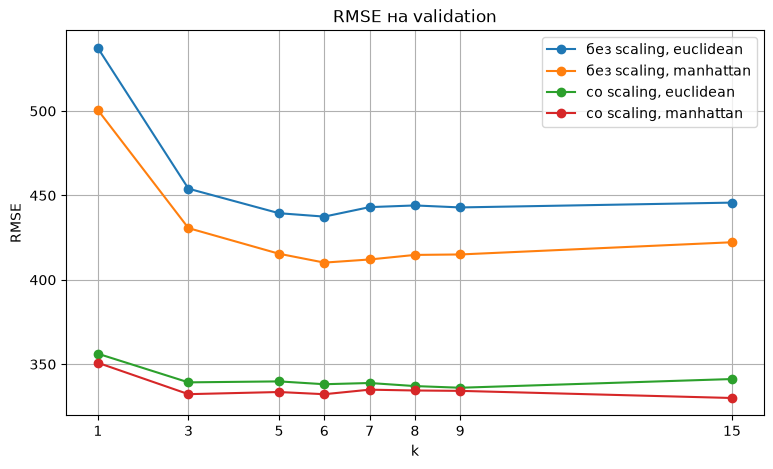

In [22]:
plt.figure(figsize=(9, 5))

for (scaling, distance), group in validation_results.groupby(["scaling", "distance"]):
    group = group.sort_values("k")
    plt.plot(group["k"], group["RMSE"], marker="o", label=f"{scaling}, {distance}")

plt.title("RMSE на validation")
plt.xlabel("k")
plt.ylabel("RMSE")
plt.xticks(k_values)
plt.legend()
plt.grid()
plt.show()

## Итоговое сравнение

In [23]:
best = validation_results.sort_values("RMSE").iloc[0]
best_X_train = X_train_scaled if best["scaling"] == "со scaling" else X_train_unscaled
best_X_test = X_test_scaled if best["scaling"] == "со scaling" else X_test_unscaled

best_model = KNN(
    k=int(best["k"]),
    task="regression",
    distance=best["distance"],
)
best_model.fit(best_X_train, y_train)
test_pred = best_model.predict(best_X_test)

baseline_pred = np.full(len(y_test), y_train.mean())

comparison = pd.DataFrame([
    ["KNN", mae(y_test, test_pred), rmse(y_test, test_pred), r2_score(y_test, test_pred)],
    ["Baseline", mae(y_test, baseline_pred), rmse(y_test, baseline_pred), r2_score(y_test, baseline_pred)],
], columns=["model", "MAE", "RMSE", "R2"]).set_index("model")

print("Лучшие параметры:", int(best["k"]), best["distance"], best["scaling"])
comparison.round(3)

Лучшие параметры: 15 manhattan со scaling


,MAE,RMSE,R2
model,,,
KNN,216.323,319.491,0.767
Baseline,533.108,662.447,-0.000


## Вывод

по validation выбрана модель с `k = 15`, Manhattan distance и scaling. На test получили MAE $= 216.3$, RMSE $= 319.5$ и $R^2 = 0.767$.

baseline, который всегда предсказывает среднее train, дал RMSE $= 662.4$ и $R^2 \approx 0$. 

KNN **заметно лучше** baseline и объясняет около 76.7% разброса целевой переменной.